In [1]:
import torch
import pyro
import pyro.distributions as dist
from pyro.infer import SVI, Trace_ELBO, Predictive
from pyro.infer.autoguide import AutoNormal
from pyro.optim import ClippedAdam

pyro.clear_param_store()

torch.set_default_dtype(torch.float32)

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

train_df = pd.read_parquet("airport_15min_train.parquet")
test_df = pd.read_parquet("airport_15min_test.parquet")

train_df["timestamp"] = pd.to_datetime(train_df["timestamp"], utc=True)
test_df["timestamp"] = pd.to_datetime(test_df["timestamp"], utc=True)

train_df.head()

,timestamp,ins,outs,total,outs_share,slot,weekday,month,is_weekend
0,2024-04-01 00:00:00+00:00,413.0,84.0,497.0,0.169014,0,0,3,0
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138,1,0,3,0
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912,2,0,3,0
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639,3,0,3,0
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481,4,0,3,0


# Model 1 - init

In [3]:
# Preparing tensors

train_df = train_df.sort_values("timestamp").reset_index(drop=True)
test_df = test_df.sort_values("timestamp").reset_index(drop=True)

slot_train = torch.tensor(train_df["slot"].values, dtype=torch.long)
total_train = torch.tensor(train_df["total"].values, dtype=torch.float32)
outs_train = torch.tensor(train_df["outs"].values, dtype=torch.float32)

slot_test = torch.tensor(test_df["slot"].values, dtype=torch.long)
total_test = torch.tensor(test_df["total"].values, dtype=torch.float32)
outs_test = torch.tensor(test_df["outs"].values, dtype=torch.float32)

In [9]:
def airport_model(slot, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 96

    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    log_lambda = mu + slot_total_effect[slot]
    lambda_ = torch.exp(log_lambda)

    logits_p = eta + slot_dir_effect[slot]

    with pyro.plate("data", n):

        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [10]:
guide = AutoNormal(airport_model)

pyro.clear_param_store()


optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi = SVI(airport_model, guide, optimizer, loss=Trace_ELBO())

losses = []

num_steps = 3000

for step in range(num_steps):
    loss = svi.step(slot_train, total_train, outs_train)
    losses.append(loss / len(train_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses[-1]:.2f}")

step 0000 | loss per obs = 243.75
step 0300 | loss per obs = 13.15
step 0600 | loss per obs = 12.79
step 0900 | loss per obs = 12.79
step 1200 | loss per obs = 12.78
step 1500 | loss per obs = 12.78
step 1800 | loss per obs = 12.78
step 2100 | loss per obs = 12.78
step 2400 | loss per obs = 12.78
step 2700 | loss per obs = 12.78


In [17]:
predictive = Predictive(
    airport_model,
    guide=guide,
    num_samples=500,
    return_sites=("total", "outs")
)

samples = predictive(slot_test, None, None)

total_samples = samples["total"].detach().cpu().numpy()
outs_samples = samples["outs"].detach().cpu().numpy()

total_pred_mean = total_samples.mean(axis=0)
outs_pred_mean = outs_samples.mean(axis=0)

test_df = test_df.copy()

test_df["pyro_total_mean"] = total_pred_mean
test_df["pyro_outs_mean"] = outs_pred_mean
test_df["pyro_ins_mean"] = test_df["pyro_total_mean"] - test_df["pyro_outs_mean"]
test_df["pyro_outs_share_mean"] = (
    test_df["pyro_outs_mean"] / np.maximum(test_df["pyro_total_mean"], 1)
)

test_df[[
    "total",
    "outs",
    "pyro_total_mean",
    "pyro_outs_mean",
    "pyro_ins_mean",
    "pyro_outs_share_mean"
]].head()

,total,outs,pyro_total_mean,pyro_outs_mean,pyro_ins_mean,pyro_outs_share_mean
0,187.0,76.0,267.648010,77.559998,190.088013,0.289784
1,317.0,84.0,239.880005,66.031998,173.848007,0.275271
2,219.0,75.0,211.746002,65.636002,146.110001,0.309975
3,162.0,74.0,187.753998,54.980000,132.774002,0.292830
4,107.0,35.0,185.292007,55.094002,130.197998,0.297336


In [18]:
print(test_df.shape)
print(total_samples.shape)
print(outs_samples.shape)

(13822, 31)
(500, 13822)
(500, 13822)


# Evaluating Pyro Model

In [19]:
def mae(y, yhat):
    return np.mean(np.abs(y - yhat))

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

pyro_metrics = {
    "total_mae": mae(test_df["total"], test_df["pyro_total_mean"]),
    "total_rmse": rmse(test_df["total"], test_df["pyro_total_mean"]),
    "outs_mae": mae(test_df["outs"], test_df["pyro_outs_mean"]),
    "outs_rmse": rmse(test_df["outs"], test_df["pyro_outs_mean"]),
    "ins_mae": mae(test_df["ins"], test_df["pyro_ins_mean"]),
    "ins_rmse": rmse(test_df["ins"], test_df["pyro_ins_mean"]),
    "direction_mae": mae(test_df["outs_share"], test_df["pyro_outs_share_mean"]),
}

true_direction = test_df["outs"] > test_df["ins"]
pred_direction = test_df["pyro_outs_mean"] > test_df["pyro_ins_mean"]

pyro_metrics["direction_accuracy"] = np.mean(true_direction == pred_direction)

pyro_metrics

{'total_mae': np.float64(77.70922652313426),
 'total_rmse': np.float64(100.13134754240224),
 'outs_mae': np.float64(42.31844851429393),
 'outs_rmse': np.float64(56.42212503506528),
 'ins_mae': np.float64(43.428643924181586),
 'ins_rmse': np.float64(58.057135965109026),
 'direction_mae': np.float64(0.08789713674558694),
 'direction_accuracy': np.float64(0.8081319635363913)}

In [20]:
baseline_results = pd.read_csv("baseline_results.csv", index_col=0)

comparison = baseline_results.copy()
comparison.loc["pyro_slot_model"] = pyro_metrics

comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,77.709227,100.131348,42.318449,56.422125,43.428644,58.057136,0.087897,0.808132


In [21]:
total_coverage = np.mean(
    (test_df["total"] >= test_df["pyro_total_q05"]) &
    (test_df["total"] <= test_df["pyro_total_q95"])
)

outs_coverage = np.mean(
    (test_df["outs"] >= test_df["pyro_outs_q05"]) &
    (test_df["outs"] <= test_df["pyro_outs_q95"])
)

share_coverage = np.mean(
    (test_df["outs_share"] >= test_df["pyro_outs_share_q05"]) &
    (test_df["outs_share"] <= test_df["pyro_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage:.3f}")
print(f"Outs 90% coverage:       {outs_coverage:.3f}")
print(f"Out-share 90% coverage:  {share_coverage:.3f}")

Total 90% coverage:      0.890
Outs 90% coverage:       0.907
Out-share 90% coverage:  0.441


# Model 2: slot + weekday

In [23]:
weekday_train = torch.tensor(train_df["weekday"].values, dtype=torch.long)
weekday_test = torch.tensor(test_df["weekday"].values, dtype=torch.long)

def airport_model_slot_weekday(slot, weekday, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 96
    n_weekdays = 7

    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    log_lambda = (
        mu
        + slot_total_effect[slot]
        + weekday_total_effect[weekday]
    )

    lambda_ = torch.exp(log_lambda)

    logits_p = (
        eta
        + slot_dir_effect[slot]
        + weekday_dir_effect[weekday]
    )

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [24]:
pyro.clear_param_store()

guide_sw = AutoNormal(airport_model_slot_weekday)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi = SVI(airport_model_slot_weekday, guide_sw, optimizer, loss=Trace_ELBO())

losses_sw = []

num_steps = 3000

for step in range(num_steps):
    loss = svi.step(slot_train, weekday_train, total_train, outs_train)
    losses_sw.append(loss / len(train_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_sw[-1]:.2f}")

step 0000 | loss per obs = 248.02
step 0300 | loss per obs = 12.88
step 0600 | loss per obs = 12.73
step 0900 | loss per obs = 12.69
step 1200 | loss per obs = 12.70
step 1500 | loss per obs = 12.69
step 1800 | loss per obs = 12.69
step 2100 | loss per obs = 12.69
step 2400 | loss per obs = 12.68
step 2700 | loss per obs = 12.68


In [25]:
predictive_sw = Predictive(
    airport_model_slot_weekday,
    guide=guide_sw,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_sw = predictive_sw(slot_test, weekday_test, None, None)

total_samples_sw = samples_sw["total"].detach().cpu().numpy()
outs_samples_sw = samples_sw["outs"].detach().cpu().numpy()

test_df["pyro_sw_total_mean"] = total_samples_sw.mean(axis=0)
test_df["pyro_sw_outs_mean"] = outs_samples_sw.mean(axis=0)
test_df["pyro_sw_ins_mean"] = test_df["pyro_sw_total_mean"] - test_df["pyro_sw_outs_mean"]
test_df["pyro_sw_outs_share_mean"] = (
    test_df["pyro_sw_outs_mean"] / np.maximum(test_df["pyro_sw_total_mean"], 1)
)

test_df["pyro_sw_total_q05"] = np.quantile(total_samples_sw, 0.05, axis=0)
test_df["pyro_sw_total_q95"] = np.quantile(total_samples_sw, 0.95, axis=0)

test_df["pyro_sw_outs_q05"] = np.quantile(outs_samples_sw, 0.05, axis=0)
test_df["pyro_sw_outs_q95"] = np.quantile(outs_samples_sw, 0.95, axis=0)

outs_share_samples_sw = outs_samples_sw / np.maximum(total_samples_sw, 1)

test_df["pyro_sw_outs_share_q05"] = np.quantile(outs_share_samples_sw, 0.05, axis=0)
test_df["pyro_sw_outs_share_q95"] = np.quantile(outs_share_samples_sw, 0.95, axis=0)

In [26]:
pyro_sw_metrics = {
    "total_mae": mae(test_df["total"], test_df["pyro_sw_total_mean"]),
    "total_rmse": rmse(test_df["total"], test_df["pyro_sw_total_mean"]),
    "outs_mae": mae(test_df["outs"], test_df["pyro_sw_outs_mean"]),
    "outs_rmse": rmse(test_df["outs"], test_df["pyro_sw_outs_mean"]),
    "ins_mae": mae(test_df["ins"], test_df["pyro_sw_ins_mean"]),
    "ins_rmse": rmse(test_df["ins"], test_df["pyro_sw_ins_mean"]),
    "direction_mae": mae(test_df["outs_share"], test_df["pyro_sw_outs_share_mean"]),
}

true_direction = test_df["outs"] > test_df["ins"]
pred_direction_sw = test_df["pyro_sw_outs_mean"] > test_df["pyro_sw_ins_mean"]

pyro_sw_metrics["direction_accuracy"] = np.mean(true_direction == pred_direction_sw)

comparison.loc["pyro_slot_weekday_model"] = pyro_sw_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,77.709227,100.131348,42.318449,56.422125,43.428644,58.057136,0.087897,0.808132
pyro_slot_weekday_model,74.948653,96.662988,41.197572,55.021653,42.072216,55.903204,0.087823,0.808566


In [27]:
total_coverage_sw = np.mean(
    (test_df["total"] >= test_df["pyro_sw_total_q05"]) &
    (test_df["total"] <= test_df["pyro_sw_total_q95"])
)

outs_coverage_sw = np.mean(
    (test_df["outs"] >= test_df["pyro_sw_outs_q05"]) &
    (test_df["outs"] <= test_df["pyro_sw_outs_q95"])
)

share_coverage_sw = np.mean(
    (test_df["outs_share"] >= test_df["pyro_sw_outs_share_q05"]) &
    (test_df["outs_share"] <= test_df["pyro_sw_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_sw:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_sw:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_sw:.3f}")

Total 90% coverage:      0.886
Outs 90% coverage:       0.907
Out-share 90% coverage:  0.432


# Model 3

In [28]:
train_df = train_df.sort_values("timestamp").reset_index(drop=True)
test_df = test_df.sort_values("timestamp").reset_index(drop=True)

# combine first so the lag at the train/test boundary is correct
full_df = pd.concat(
    [train_df.assign(split="train"), test_df.assign(split="test")],
    ignore_index=True
).sort_values("timestamp").reset_index(drop=True)

full_df["lag_total"] = full_df["total"].shift(1)
full_df["lag_outs_share"] = full_df["outs_share"].shift(1)

# remove first row because it has no lag
full_df = full_df.dropna(subset=["lag_total", "lag_outs_share"]).copy()

# log transform total lag
full_df["log_lag_total"] = np.log1p(full_df["lag_total"])

# stabilize outs_share lag before logit
eps = 1e-4
full_df["lag_outs_share_clipped"] = full_df["lag_outs_share"].clip(eps, 1 - eps)
full_df["logit_lag_outs_share"] = np.log(
    full_df["lag_outs_share_clipped"] / (1 - full_df["lag_outs_share_clipped"])
)

# standardize lag features using TRAIN ONLY
train_mask = full_df["split"] == "train"

log_lag_mean = full_df.loc[train_mask, "log_lag_total"].mean()
log_lag_std = full_df.loc[train_mask, "log_lag_total"].std()

dir_lag_mean = full_df.loc[train_mask, "logit_lag_outs_share"].mean()
dir_lag_std = full_df.loc[train_mask, "logit_lag_outs_share"].std()

full_df["log_lag_total_std"] = (
    full_df["log_lag_total"] - log_lag_mean
) / log_lag_std

full_df["logit_lag_outs_share_std"] = (
    full_df["logit_lag_outs_share"] - dir_lag_mean
) / dir_lag_std

train_ar_df = full_df[full_df["split"] == "train"].copy()
test_ar_df = full_df[full_df["split"] == "test"].copy()

print(train_ar_df.shape, test_ar_df.shape)
train_ar_df.head()

(55288, 49) (13822, 49)


,timestamp,ins,outs,total,outs_share,slot,weekday,month,is_weekend,split,...,pyro_sw_outs_q95,pyro_sw_outs_share_q05,pyro_sw_outs_share_q95,lag_total,lag_outs_share,log_lag_total,lag_outs_share_clipped,logit_lag_outs_share,log_lag_total_std,logit_lag_outs_share_std
1,2024-04-01 00:15:00+00:00,182.0,36.0,218.0,0.165138,1,0,3,0,train,...,NaN,NaN,NaN,497.0,0.169014,6.210600,0.169014,-1.592631,0.799727,-1.303012
2,2024-04-01 00:30:00+00:00,104.0,55.0,159.0,0.345912,2,0,3,0,train,...,NaN,NaN,NaN,218.0,0.165138,5.389072,0.165138,-1.620488,0.027772,-1.322389
3,2024-04-01 00:45:00+00:00,49.0,34.0,83.0,0.409639,3,0,3,0,train,...,NaN,NaN,NaN,159.0,0.345912,5.075174,0.345912,-0.637058,-0.267184,-0.638341
4,2024-04-01 01:00:00+00:00,28.0,26.0,54.0,0.481481,4,0,3,0,train,...,NaN,NaN,NaN,83.0,0.409639,4.430817,0.409639,-0.365460,-0.872659,-0.449425
5,2024-04-01 01:15:00+00:00,41.0,4.0,45.0,0.088889,5,0,3,0,train,...,NaN,NaN,NaN,54.0,0.481481,4.007333,0.481481,-0.074108,-1.270588,-0.246768


In [29]:
slot_train_ar = torch.tensor(train_ar_df["slot"].values, dtype=torch.long)
weekday_train_ar = torch.tensor(train_ar_df["weekday"].values, dtype=torch.long)

total_train_ar = torch.tensor(train_ar_df["total"].values, dtype=torch.float32)
outs_train_ar = torch.tensor(train_ar_df["outs"].values, dtype=torch.float32)

lag_total_train_ar = torch.tensor(
    train_ar_df["log_lag_total_std"].values,
    dtype=torch.float32
)

slot_test_ar = torch.tensor(test_ar_df["slot"].values, dtype=torch.long)
weekday_test_ar = torch.tensor(test_ar_df["weekday"].values, dtype=torch.long)

total_test_ar = torch.tensor(test_ar_df["total"].values, dtype=torch.float32)
outs_test_ar = torch.tensor(test_ar_df["outs"].values, dtype=torch.float32)

lag_total_test_ar = torch.tensor(
    test_ar_df["log_lag_total_std"].values,
    dtype=torch.float32
)

In [30]:
def airport_model_ar_total(slot, weekday, lag_total, total_obs=None, outs_obs=None):
    n = len(slot)
    n_slots = 96
    n_weekdays = 7

    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    alpha_lag = pyro.sample("alpha_lag", dist.Normal(0.0, 0.5))

    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    log_lambda = (
        mu
        + slot_total_effect[slot]
        + weekday_total_effect[weekday]
        + alpha_lag * lag_total
    )

    lambda_ = torch.exp(log_lambda)

    logits_p = (
        eta
        + slot_dir_effect[slot]
        + weekday_dir_effect[weekday]
    )

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs
        )

In [31]:
pyro.clear_param_store()

guide_ar = AutoNormal(airport_model_ar_total)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi_ar = SVI(airport_model_ar_total, guide_ar, optimizer, loss=Trace_ELBO())

losses_ar = []

num_steps = 3000

for step in range(num_steps):
    loss = svi_ar.step(
        slot_train_ar,
        weekday_train_ar,
        lag_total_train_ar,
        total_train_ar,
        outs_train_ar,
    )

    losses_ar.append(loss / len(train_ar_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_ar[-1]:.2f}")

step 0000 | loss per obs = 232.62
step 0300 | loss per obs = 12.87
step 0600 | loss per obs = 12.53
step 0900 | loss per obs = 12.56
step 1200 | loss per obs = 12.51
step 1500 | loss per obs = 12.50
step 1800 | loss per obs = 12.50
step 2100 | loss per obs = 12.50
step 2400 | loss per obs = 12.50
step 2700 | loss per obs = 12.50


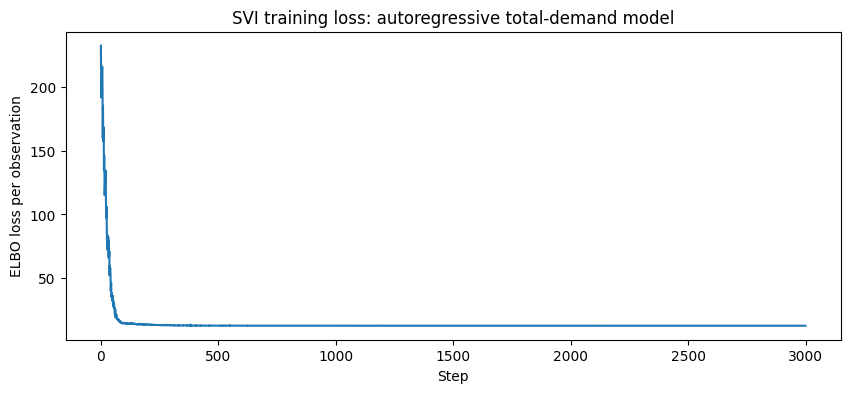

In [32]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses_ar)
ax.set_title("SVI training loss: autoregressive total-demand model")
ax.set_xlabel("Step")
ax.set_ylabel("ELBO loss per observation")
plt.show()

In [33]:
predictive_ar = Predictive(
    airport_model_ar_total,
    guide=guide_ar,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_ar = predictive_ar(
    slot_test_ar,
    weekday_test_ar,
    lag_total_test_ar,
    None,
    None,
)

total_samples_ar = samples_ar["total"].detach().cpu().numpy()
outs_samples_ar = samples_ar["outs"].detach().cpu().numpy()

test_ar_df["pyro_ar_total_mean"] = total_samples_ar.mean(axis=0)
test_ar_df["pyro_ar_outs_mean"] = outs_samples_ar.mean(axis=0)
test_ar_df["pyro_ar_ins_mean"] = (
    test_ar_df["pyro_ar_total_mean"] - test_ar_df["pyro_ar_outs_mean"]
)
test_ar_df["pyro_ar_outs_share_mean"] = (
    test_ar_df["pyro_ar_outs_mean"] / np.maximum(test_ar_df["pyro_ar_total_mean"], 1)
)

In [34]:
test_ar_df["pyro_ar_total_q05"] = np.quantile(total_samples_ar, 0.05, axis=0)
test_ar_df["pyro_ar_total_q95"] = np.quantile(total_samples_ar, 0.95, axis=0)

test_ar_df["pyro_ar_outs_q05"] = np.quantile(outs_samples_ar, 0.05, axis=0)
test_ar_df["pyro_ar_outs_q95"] = np.quantile(outs_samples_ar, 0.95, axis=0)

outs_share_samples_ar = outs_samples_ar / np.maximum(total_samples_ar, 1)

test_ar_df["pyro_ar_outs_share_q05"] = np.quantile(
    outs_share_samples_ar, 0.05, axis=0
)

test_ar_df["pyro_ar_outs_share_q95"] = np.quantile(
    outs_share_samples_ar, 0.95, axis=0
)

In [35]:
pyro_ar_metrics = {
    "total_mae": mae(test_ar_df["total"], test_ar_df["pyro_ar_total_mean"]),
    "total_rmse": rmse(test_ar_df["total"], test_ar_df["pyro_ar_total_mean"]),
    "outs_mae": mae(test_ar_df["outs"], test_ar_df["pyro_ar_outs_mean"]),
    "outs_rmse": rmse(test_ar_df["outs"], test_ar_df["pyro_ar_outs_mean"]),
    "ins_mae": mae(test_ar_df["ins"], test_ar_df["pyro_ar_ins_mean"]),
    "ins_rmse": rmse(test_ar_df["ins"], test_ar_df["pyro_ar_ins_mean"]),
    "direction_mae": mae(
        test_ar_df["outs_share"],
        test_ar_df["pyro_ar_outs_share_mean"]
    ),
}

true_direction_ar = test_ar_df["outs"] > test_ar_df["ins"]
pred_direction_ar = test_ar_df["pyro_ar_outs_mean"] > test_ar_df["pyro_ar_ins_mean"]

pyro_ar_metrics["direction_accuracy"] = np.mean(
    true_direction_ar == pred_direction_ar
)

comparison.loc["pyro_ar_total_model"] = pyro_ar_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,77.709227,100.131348,42.318449,56.422125,43.428644,58.057136,0.087897,0.808132
pyro_slot_weekday_model,74.948653,96.662988,41.197572,55.021653,42.072216,55.903204,0.087823,0.808566
pyro_ar_total_model,51.401234,67.177277,31.444272,43.349536,31.082508,42.238284,0.087755,0.808566


In [36]:
total_coverage_ar = np.mean(
    (test_ar_df["total"] >= test_ar_df["pyro_ar_total_q05"]) &
    (test_ar_df["total"] <= test_ar_df["pyro_ar_total_q95"])
)

outs_coverage_ar = np.mean(
    (test_ar_df["outs"] >= test_ar_df["pyro_ar_outs_q05"]) &
    (test_ar_df["outs"] <= test_ar_df["pyro_ar_outs_q95"])
)

share_coverage_ar = np.mean(
    (test_ar_df["outs_share"] >= test_ar_df["pyro_ar_outs_share_q05"]) &
    (test_ar_df["outs_share"] <= test_ar_df["pyro_ar_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_ar:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_ar:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_ar:.3f}")

Total 90% coverage:      0.900
Outs 90% coverage:       0.903
Out-share 90% coverage:  0.447


# Model 4

*Does previous total traffic help predict current total traffic, and does previous directionality help predict current directionality?*

In [37]:
lag_dir_train_ar = torch.tensor(
    train_ar_df["logit_lag_outs_share_std"].values,
    dtype=torch.float32
)

lag_dir_test_ar = torch.tensor(
    test_ar_df["logit_lag_outs_share_std"].values,
    dtype=torch.float32
)

In [38]:
def airport_model_ar_total_direction(
    slot,
    weekday,
    lag_total,
    lag_dir,
    total_obs=None,
    outs_obs=None,
):
    n = len(slot)
    n_slots = 96
    n_weekdays = 7

    # global intercepts
    mu = pyro.sample("mu", dist.Normal(5.5, 1.0))
    eta = pyro.sample("eta", dist.Normal(0.0, 1.0))

    # autoregressive coefficients
    alpha_lag_total = pyro.sample("alpha_lag_total", dist.Normal(0.0, 0.5))
    gamma_lag_dir = pyro.sample("gamma_lag_dir", dist.Normal(0.0, 0.5))

    # hierarchical scales
    sigma_slot_total = pyro.sample("sigma_slot_total", dist.HalfNormal(1.0))
    sigma_slot_dir = pyro.sample("sigma_slot_dir", dist.HalfNormal(1.0))

    sigma_weekday_total = pyro.sample("sigma_weekday_total", dist.HalfNormal(0.5))
    sigma_weekday_dir = pyro.sample("sigma_weekday_dir", dist.HalfNormal(0.5))

    # overdispersion for total demand
    phi = pyro.sample("phi", dist.HalfNormal(10.0))

    # slot effects
    with pyro.plate("slots", n_slots):
        slot_total_raw = pyro.sample("slot_total_raw", dist.Normal(0.0, 1.0))
        slot_dir_raw = pyro.sample("slot_dir_raw", dist.Normal(0.0, 1.0))

    # weekday effects
    with pyro.plate("weekdays", n_weekdays):
        weekday_total_raw = pyro.sample("weekday_total_raw", dist.Normal(0.0, 1.0))
        weekday_dir_raw = pyro.sample("weekday_dir_raw", dist.Normal(0.0, 1.0))

    slot_total_effect = sigma_slot_total * slot_total_raw
    slot_dir_effect = sigma_slot_dir * slot_dir_raw

    weekday_total_effect = sigma_weekday_total * weekday_total_raw
    weekday_dir_effect = sigma_weekday_dir * weekday_dir_raw

    # total-demand model
    log_lambda = (
        mu
        + slot_total_effect[slot]
        + weekday_total_effect[weekday]
        + alpha_lag_total * lag_total
    )

    lambda_ = torch.exp(log_lambda)

    # directional model
    logits_p = (
        eta
        + slot_dir_effect[slot]
        + weekday_dir_effect[weekday]
        + gamma_lag_dir * lag_dir
    )

    with pyro.plate("data", n):
        total = pyro.sample(
            "total",
            dist.NegativeBinomial(
                total_count=phi,
                logits=torch.log(lambda_) - torch.log(phi)
            ),
            obs=total_obs,
        )

        binomial_total = total_obs if total_obs is not None else total

        pyro.sample(
            "outs",
            dist.Binomial(
                total_count=binomial_total,
                logits=logits_p
            ),
            obs=outs_obs,
        )

In [39]:
pyro.clear_param_store()

guide_ard = AutoNormal(airport_model_ar_total_direction)

optimizer = ClippedAdam({"lr": 0.01, "clip_norm": 10.0})
svi_ard = SVI(
    airport_model_ar_total_direction,
    guide_ard,
    optimizer,
    loss=Trace_ELBO()
)

losses_ard = []

num_steps = 3000

for step in range(num_steps):
    loss = svi_ard.step(
        slot_train_ar,
        weekday_train_ar,
        lag_total_train_ar,
        lag_dir_train_ar,
        total_train_ar,
        outs_train_ar,
    )

    losses_ard.append(loss / len(train_ar_df))

    if step % 300 == 0:
        print(f"step {step:04d} | loss per obs = {losses_ard[-1]:.2f}")

step 0000 | loss per obs = 251.32
step 0300 | loss per obs = 12.50
step 0600 | loss per obs = 12.20
step 0900 | loss per obs = 12.17
step 1200 | loss per obs = 12.15
step 1500 | loss per obs = 12.15
step 1800 | loss per obs = 12.15
step 2100 | loss per obs = 12.15
step 2400 | loss per obs = 12.15
step 2700 | loss per obs = 12.14


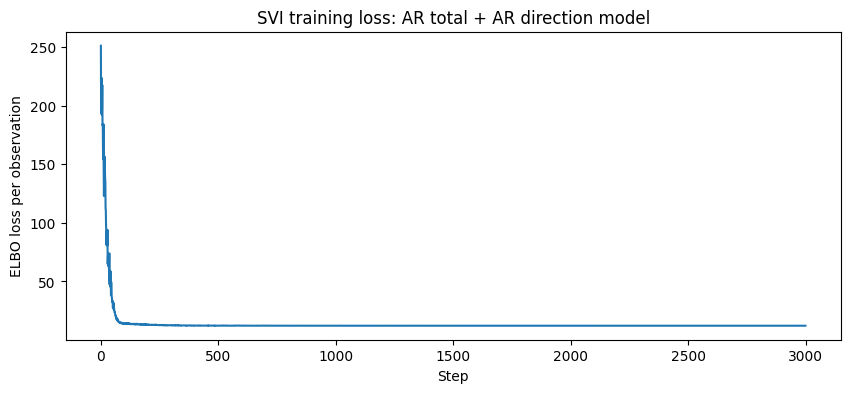

In [40]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(losses_ard)
ax.set_title("SVI training loss: AR total + AR direction model")
ax.set_xlabel("Step")
ax.set_ylabel("ELBO loss per observation")
plt.show()

Posterior predictive sampling:

In [41]:
predictive_ard = Predictive(
    airport_model_ar_total_direction,
    guide=guide_ard,
    num_samples=500,
    return_sites=("total", "outs")
)

samples_ard = predictive_ard(
    slot_test_ar,
    weekday_test_ar,
    lag_total_test_ar,
    lag_dir_test_ar,
    None,
    None,
)

total_samples_ard = samples_ard["total"].detach().cpu().numpy()
outs_samples_ard = samples_ard["outs"].detach().cpu().numpy()

In [42]:
test_ar_df["pyro_ard_total_mean"] = total_samples_ard.mean(axis=0)
test_ar_df["pyro_ard_outs_mean"] = outs_samples_ard.mean(axis=0)

test_ar_df["pyro_ard_ins_mean"] = (
    test_ar_df["pyro_ard_total_mean"] - test_ar_df["pyro_ard_outs_mean"]
)

test_ar_df["pyro_ard_outs_share_mean"] = (
    test_ar_df["pyro_ard_outs_mean"] / np.maximum(test_ar_df["pyro_ard_total_mean"], 1)
)

In [43]:
test_ar_df["pyro_ard_total_q05"] = np.quantile(total_samples_ard, 0.05, axis=0)
test_ar_df["pyro_ard_total_q95"] = np.quantile(total_samples_ard, 0.95, axis=0)

test_ar_df["pyro_ard_outs_q05"] = np.quantile(outs_samples_ard, 0.05, axis=0)
test_ar_df["pyro_ard_outs_q95"] = np.quantile(outs_samples_ard, 0.95, axis=0)

outs_share_samples_ard = outs_samples_ard / np.maximum(total_samples_ard, 1)

test_ar_df["pyro_ard_outs_share_q05"] = np.quantile(
    outs_share_samples_ard,
    0.05,
    axis=0
)

test_ar_df["pyro_ard_outs_share_q95"] = np.quantile(
    outs_share_samples_ard,
    0.95,
    axis=0
)

In [44]:
pyro_ard_metrics = {
    "total_mae": mae(test_ar_df["total"], test_ar_df["pyro_ard_total_mean"]),
    "total_rmse": rmse(test_ar_df["total"], test_ar_df["pyro_ard_total_mean"]),
    "outs_mae": mae(test_ar_df["outs"], test_ar_df["pyro_ard_outs_mean"]),
    "outs_rmse": rmse(test_ar_df["outs"], test_ar_df["pyro_ard_outs_mean"]),
    "ins_mae": mae(test_ar_df["ins"], test_ar_df["pyro_ard_ins_mean"]),
    "ins_rmse": rmse(test_ar_df["ins"], test_ar_df["pyro_ard_ins_mean"]),
    "direction_mae": mae(
        test_ar_df["outs_share"],
        test_ar_df["pyro_ard_outs_share_mean"]
    ),
}

true_direction_ard = test_ar_df["outs"] > test_ar_df["ins"]
pred_direction_ard = test_ar_df["pyro_ard_outs_mean"] > test_ar_df["pyro_ard_ins_mean"]

pyro_ard_metrics["direction_accuracy"] = np.mean(
    true_direction_ard == pred_direction_ard
)

comparison.loc["pyro_ar_total_direction_model"] = pyro_ard_metrics
comparison

,total_mae,total_rmse,outs_mae,outs_rmse,ins_mae,ins_rmse,direction_mae,direction_accuracy
global,131.503793,160.122811,81.755828,96.869366,69.070972,84.139071,0.161458,0.590870
slot,75.831100,97.738296,41.842536,55.594710,42.235025,56.325320,0.086621,0.808060
slot_weekday,64.074949,83.278428,35.838424,48.080332,37.193288,50.036198,0.082968,0.808132
pyro_slot_model,77.709227,100.131348,42.318449,56.422125,43.428644,58.057136,0.087897,0.808132
pyro_slot_weekday_model,74.948653,96.662988,41.197572,55.021653,42.072216,55.903204,0.087823,0.808566
pyro_ar_total_model,51.401234,67.177277,31.444272,43.349536,31.082508,42.238284,0.087755,0.808566
pyro_ar_total_direction_model,49.226605,64.962251,30.184816,42.183020,29.032793,39.945584,0.084799,0.808711


In [45]:
total_coverage_ard = np.mean(
    (test_ar_df["total"] >= test_ar_df["pyro_ard_total_q05"]) &
    (test_ar_df["total"] <= test_ar_df["pyro_ard_total_q95"])
)

outs_coverage_ard = np.mean(
    (test_ar_df["outs"] >= test_ar_df["pyro_ard_outs_q05"]) &
    (test_ar_df["outs"] <= test_ar_df["pyro_ard_outs_q95"])
)

share_coverage_ard = np.mean(
    (test_ar_df["outs_share"] >= test_ar_df["pyro_ard_outs_share_q05"]) &
    (test_ar_df["outs_share"] <= test_ar_df["pyro_ard_outs_share_q95"])
)

print(f"Total 90% coverage:      {total_coverage_ard:.3f}")
print(f"Outs 90% coverage:       {outs_coverage_ard:.3f}")
print(f"Out-share 90% coverage:  {share_coverage_ard:.3f}")

Total 90% coverage:      0.904
Outs 90% coverage:       0.904
Out-share 90% coverage:  0.474


In [46]:
posterior_ard = Predictive(
    airport_model_ar_total_direction,
    guide=guide_ard,
    num_samples=1000,
    return_sites=("alpha_lag_total", "gamma_lag_dir")
)

coef_samples = posterior_ard(
    slot_train_ar[:10],
    weekday_train_ar[:10],
    lag_total_train_ar[:10],
    lag_dir_train_ar[:10],
    None,
    None,
)

alpha_samples = coef_samples["alpha_lag_total"].detach().cpu().numpy()
gamma_samples = coef_samples["gamma_lag_dir"].detach().cpu().numpy()

print("alpha_lag_total:")
print("mean:", alpha_samples.mean())
print("90% CI:", np.quantile(alpha_samples, [0.05, 0.95]))

print("\ngamma_lag_dir:")
print("mean:", gamma_samples.mean())
print("90% CI:", np.quantile(gamma_samples, [0.05, 0.95]))

alpha_lag_total:
mean: 0.521483
90% CI: [0.51910519 0.52384916]

gamma_lag_dir:
mean: 0.34559625
90% CI: [0.34392797 0.34733156]


# Model 5: BetaBinomial for outs